# 02 — Heart-rate estimation from wrist PPG

**Goal:** Estimate heart rate from the PPG signal, compare it with the ECG-derived reference, and understand where a simple method fails.

We'll try two straightforward approaches:
- **Raw PPG:** pick the strongest frequency in the pulse range using a periodogram.
- **Filtered PPG:** first apply a Butterworth bandpass filter, then pick the strongest frequency using Welch's spectrum.

No model training is required. **The reference heart rate is only used to evaluate predictions — never to estimate them.**

## 1. Load the subjects

Use the same subject IDs and dataset folder as in notebook 01. You can select **one or two subjects**; the code handles both. The times below are seconds from each participant's own recording start, so the same time does **not** guarantee the same activity for different subjects.

*Security: load pickle files only from the trusted dataset download; Python pickle can execute code during loading.*

In [9]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

SUBJECTS = ["S1", "S4"]
SUBJECTS = ["S1"]
DATA_FOLDER = Path("../Data/PPG_FieldStudy")

timeline = {"NO:_ACTIVITY1":	0,
 "BASELINE":	90,
 "NO_ACTIVITY2":	791,
 "STAIRS":	837,
 "NO_ACTIVITY3":	1125,
 "SOCCER":	1210,
 "NO_ACTIVITY4":	1556,
 "CYCLING":	1918,
 "NO_ACTIVITY5":	2331,
 "DRIVING":	2935,
 "NO_ACTIVITY6":	3825,
 "LUNCH":	4595,
 "WALKING":	6951,
 "NO_ACTIVITY7":	7706,
 "WORKING":	7791,
 "NO_ACTIVITY8":	8981,
 "CLEAN_BASELINE":	9077,
 "NO_ACTIVITY9":	9198}


GRAPH_START = timeline["SOCCER"] + 200
# GRAPH_START = timeline["CYCLING"] + 200
GRAPH_DURATION = 30


PPG_HZ = 64
WINDOW = 8         # 8-second windows
STEP = 2           # Move forward 2 seconds each time
MIN_HZ = 0.65      # 39 BPM
MAX_HZ = 3.5       # 210 BPM

In [10]:
recordings = {}

for subject in SUBJECTS:
    file = DATA_FOLDER / subject / f"{subject}.pkl"
    with open(file, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    recordings[subject] = {
        "ppg": np.asarray(data["signal"]["wrist"]["BVP"]).flatten(),
        "reference_hr": np.asarray(data["label"]).flatten()
    }

    print(f"{subject}: {len(recordings[subject]['ppg']):,} PPG samples, "
          f"{len(recordings[subject]['reference_hr']):,} reference labels")

S1: 589,568 PPG samples, 4,603 reference labels


## 2. Build a simple heart-rate estimator

Heartbeats produce repeated fluctuations in PPG. We find a strong frequency between **0.65 and 3.5 Hz**, then multiply it by 60 to convert it to beats per minute.

The 8-second windows match the supplied reference labels: label 0 covers 0–8 seconds, label 1 covers 2–10 seconds, and so on. The `nfft=4096` setting makes the plotted peak smoother but **does not add information** to an 8-second recording.

**Important:** With a single 8-second window, Welch's method has effectively one segment, so it provides no averaging advantage over a periodogram. This is just a modest baseline comparison, not a robust motion-correction algorithm.

In [11]:
def estimate_hr(ppg_window, method="periodogram"):
    if not np.isfinite(ppg_window).all():
        return np.nan

    if method == "welch":
        freq, power = signal.welch(ppg_window, fs=PPG_HZ,
                                   nperseg=len(ppg_window), nfft=4096)
    else:
        freq, power = signal.periodogram(ppg_window, fs=PPG_HZ, nfft=4096)

    pulse_range = (freq >= MIN_HZ) & (freq <= MAX_HZ)
    peak = freq[pulse_range][np.argmax(power[pulse_range])]
    return peak * 60

## 3. Filter PPG and estimate heart rate

A third-order Butterworth bandpass filter retains frequencies near plausible pulse rates. We apply it to the full PPG recording **before** taking windows so each 8-second window doesn't have artificial filtering edges.

For every window we compute two predictions. **Only after that** do we retrieve the matching reference label for comparison.

In [12]:
results = {}

for subject in SUBJECTS:
    ppg = recordings[subject]["ppg"]
    reference_hr = recordings[subject]["reference_hr"]

    last_index = min(
        len(reference_hr) - 1,
        (len(ppg) - WINDOW * PPG_HZ) // (STEP * PPG_HZ)
    )

    assert last_index >= 0, f"{subject}: recording is too short."
    assert np.isfinite(ppg).all(), f"{subject}: PPG contains missing/non-finite values."

    filtered_ppg = signal.sosfiltfilt(sos, ppg)
    recordings[subject]["filtered_ppg"] = filtered_ppg

    rows = []
    for i in range(last_index + 1):
        start = i * STEP * PPG_HZ
        end = start + WINDOW * PPG_HZ

        raw_bpm = estimate_hr(ppg[start:end])
        filtered_bpm = estimate_hr(filtered_ppg[start:end], method="welch")

        rows.append({
            "Time (s)": i * STEP + WINDOW / 2,
            "Raw estimate (BPM)": raw_bpm,
            "Filtered estimate (BPM)": filtered_bpm,
            "Reference HR (BPM)": reference_hr[i]
        })

    results[subject] = pd.DataFrame(rows)
    print(f"{subject}: {len(results[subject])} complete windows analyzed")

display(results[SUBJECTS[0]].head())

S1: 4603 complete windows analyzed


,Time (s),Raw estimate (BPM),Filtered estimate (BPM),Reference HR (BPM)
0,4.0,45.0000,45.0000,49.611369
1,6.0,47.8125,46.8750,50.323992
2,8.0,50.6250,53.4375,52.708336
3,10.0,53.4375,52.5000,55.640794
4,12.0,52.5000,52.5000,57.658406


## 4. Visualize the raw and filtered PPG

Inspect the **first 8 seconds** of the selected segment. The filter reduces out-of-band variation; it doesn't guarantee that the remaining peaks are genuine heartbeats.

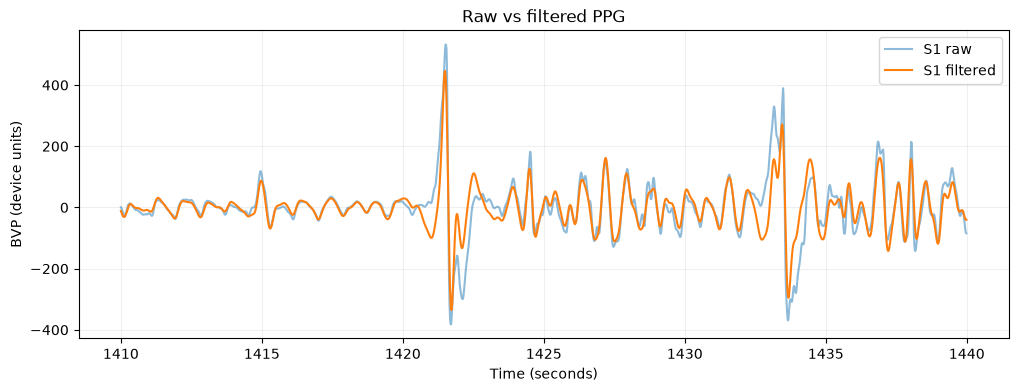

In [13]:
plt.figure(figsize=(12, 4))

for subject in SUBJECTS:
    ppg = recordings[subject]["ppg"]
    filtered_ppg = recordings[subject]["filtered_ppg"]

    start = int(GRAPH_START * PPG_HZ)
    end = int((GRAPH_START + GRAPH_DURATION) * PPG_HZ)

    assert end <= len(ppg), f"{subject}: graph segment exceeds recording."
    time = np.arange(start, end) / PPG_HZ

    plt.plot(time, ppg[start:end], alpha=0.5, label=f"{subject} raw")
    plt.plot(time, filtered_ppg[start:end], label=f"{subject} filtered")

plt.title("Raw vs filtered PPG")
plt.xlabel("Time (seconds)")
plt.ylabel("BVP (device units)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 5. See how the frequency peak becomes a heart-rate estimate

The graph shows the spectral power at candidate pulse rates for the same 8-second window. The strongest peak within the chosen range is our estimate, **not proof of a true heartbeat**.

S1: estimated HR = 69.4 BPM


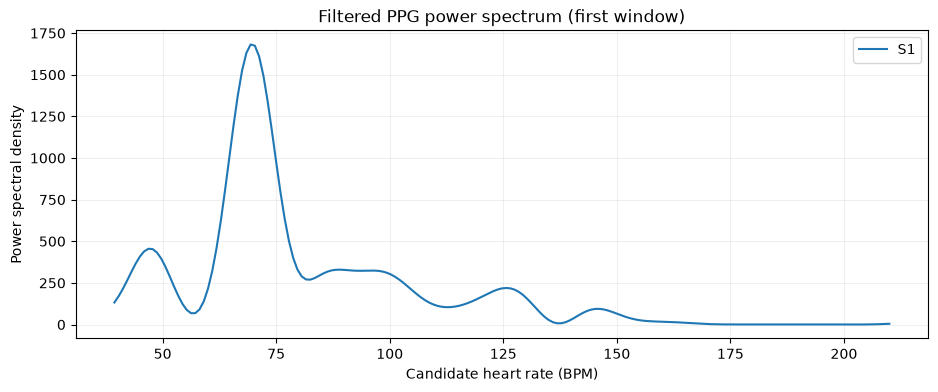

In [14]:
plt.figure(figsize=(11, 4))

for subject in SUBJECTS:
    ppg = recordings[subject]["filtered_ppg"]
    start = int(GRAPH_START * PPG_HZ)
    window = ppg[start:start + WINDOW * PPG_HZ]

    freq, power = signal.welch(window, fs=PPG_HZ,
                               nperseg=len(window), nfft=4096)
    pulse_range = (freq >= MIN_HZ) & (freq <= MAX_HZ)

    plt.plot(freq[pulse_range] * 60, power[pulse_range], label=subject)
    print(f"{subject}: estimated HR = {estimate_hr(window, method='welch'):.1f} BPM")

plt.title("Filtered PPG power spectrum (first window)")
plt.xlabel("Candidate heart rate (BPM)")
plt.ylabel("Power spectral density")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 6. Compare predictions with the reference

The ECG-derived reference is used **only here**, after both PPG estimates have been computed. Each plot compares a subject's estimates and reference over the selected interval.

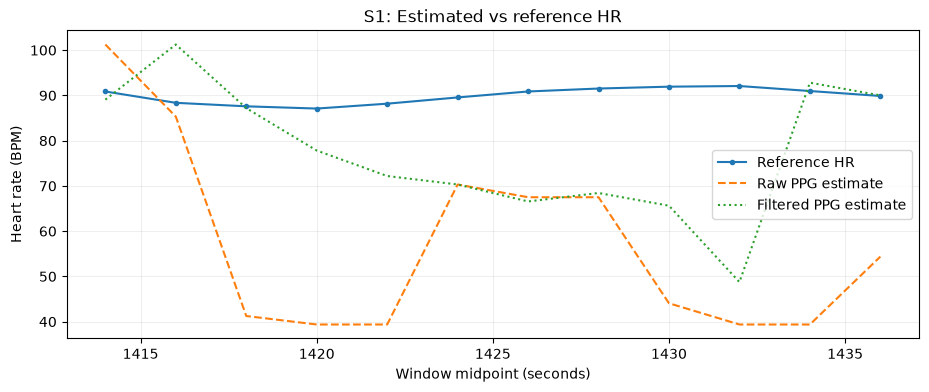

In [15]:
for subject in SUBJECTS:
    df = df[
        (df["Time (s)"] >= GRAPH_START) &
        (df["Time (s)"] <= GRAPH_START + GRAPH_DURATION)
    ]

    plt.figure(figsize=(11, 4))
    plt.plot(df["Time (s)"], df["Reference HR (BPM)"], label="Reference HR", marker=".")
    plt.plot(df["Time (s)"], df["Raw estimate (BPM)"], label="Raw PPG estimate", linestyle="--")
    plt.plot(df["Time (s)"], df["Filtered estimate (BPM)"], label="Filtered PPG estimate", linestyle=":")

    plt.title(f"{subject}: Estimated vs reference HR")
    plt.xlabel("Window midpoint (seconds)")
    plt.ylabel("Heart rate (BPM)")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

## 7. Measure estimation error

- **MAE (BPM):** average absolute difference between prediction and reference; lower is better.
- **Mean error (BPM):** average signed difference; positive values mean overestimation.

These metrics describe **only the chosen recording segment**, not performance on new participants. The overlapping windows aren't independent observations.

In [16]:
summary = []

for subject in SUBJECTS:
    df = results[subject]

    for method in ["Raw estimate (BPM)", "Filtered estimate (BPM)"]:
        error = df[method] - df["Reference HR (BPM)"]
        error = error.dropna()

        summary.append({
            "Subject": subject,
            "Method": method.replace(" estimate (BPM)", " PPG"),
            "Windows": len(error),
            "MAE (BPM)": error.abs().mean(),
            "Mean error (BPM)": error.mean()
        })

summary = pd.DataFrame(summary)
display(summary.round(2))

,Subject,Method,Windows,MAE (BPM),Mean error (BPM)
0,S1,Raw PPG,4603,11.36,-6.28
1,S1,Filtered PPG,4603,10.44,-3.69


## 8. Takeaways (fill in after running on the real data)

Write your own observations from the graphs and metrics:

- **Selected segment / activity:** …
- **Was the PPG waveform clean or distorted?** …
- **Did filtering improve MAE for S1 and/or S2?** …
- **Where were the largest errors?** …
- **What didn't work?** …
- **Limitations:** movement can create false peaks; the largest spectral peak may be a harmonic rather than the pulse; short windows limit frequency resolution; only a small number of participants and windows were evaluated; one 8-second Welch segment does not offer spectral averaging.

**Next:** More detailed evaluation, potentially comparing subjects during the *same activity* rather than using identical timestamps.